# Experimenting with pitch detection using the nesMD for CSC475 chiptune transcription project

In [1]:
#!/usr/bin/env python
# coding: utf-8

import librosa
!pip install mir_eval
!pip install mido
import mido
import mir_eval
import IPython.display as ipd
import numpy as np
import sys
import scipy as scp
import matplotlib.pyplot as plt

In [2]:
track1 = "093_DuckTales_06_07TheMoon_Track1.wav"
(x1,srate) = librosa.load(track1)
print("sampling rate =", srate)
ipd.Audio(x1, rate=srate)

sampling rate = 22050


In [20]:
# chiptune pitch_detection functions for the different NESMDB tracks
# input: array of amplitude values (from something like librosa.load(filename))
# output: array of (estimated) fundamental frequencies for each sample

# from nesmdb paper:
# "We constrain the frequency ranges of the melodic voices (pulse and triangle generators)
# to the MIDI notes on an 88-key piano keyboard (21 through 108 inclusive, though the pulse
# generators cannot produce pitches below MIDI note 32)"
def pitch_detection(x, srate, fmin=librosa.midi_to_hz(21), fmax=librosa.midi_to_hz(108), output_midi = False):
    f0s, voiced_flags, voiced_probs = librosa.pyin(x, sr=srate, fmin=fmin, fmax=fmax)
    # timestamps for sonification
    times = librosa.times_like(f0s, sr=srate)
    f0s = np.nan_to_num(f0s)
    if output_midi:
        f0s[f0s != 0] = np.rint(librosa.hz_to_midi(f0s[f0s != 0])) # round because midi is int only
    return f0s, voiced_flags, times

f0s, voiced_flags, times = pitch_detection(x1, srate)

In [21]:
def pitch_sonification(f0s, voiced_flags, times, srate):
    # sonify the f0 contour with constant amplitude and ignoring unvoiced frames
    vneg = (-1)**(~voiced_flags)
    return mir_eval.sonify.pitch_contour(times, f0s * vneg, srate)

ipd.Audio(pitch_sonification(f0s, voiced_flags, times, srate), rate=srate)

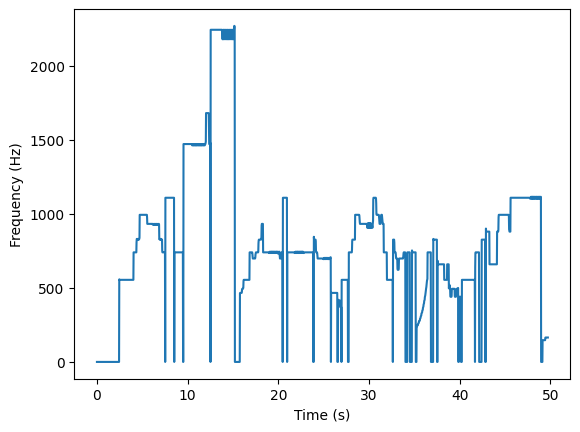

In [22]:
# visualize frequency contour
plt.plot(times, f0s)
plt.xlabel('Time (s)')
plt.ylabel('Frequency (Hz)')
plt.show()

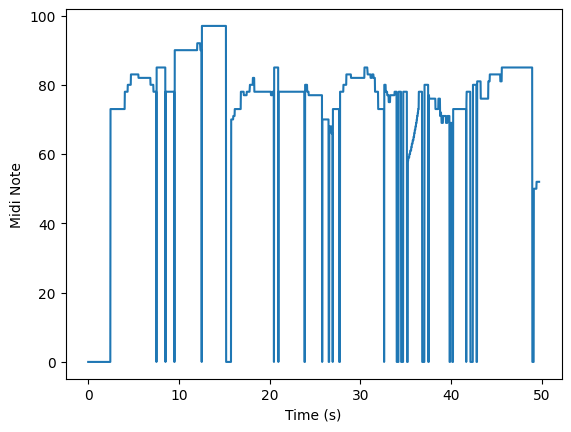

In [23]:
# visualize frequency contour as midi notes
midi_f0s, voiced_flags, times = pitch_detection(x1, srate, output_midi=True)
plt.plot(times, midi_f0s)
plt.xlabel('Time (s)')
plt.ylabel('Midi Note')
plt.show()

In [24]:
np.set_printoptions(threshold=sys.maxsize)
print(midi_f0s.shape)
print(midi_f0s)

(2142,)
[ 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0. 73. 73.
 73. 73. 73. 73. 73. 73. 73. 73. 73. 73. 73. 73. 73. 73. 73. 73. 73. 73.
 73. 73. 73. 73. 73. 73. 73. 73. 73. 73. 73. 73. 73. 73. 73. 73. 73. 73.
 73. 73. 73. 73. 73. 73. 73. 73. 73. 73. 73. 73. 73. 73. 73. 73. 73. 73.
 73. 73. 73. 73. 73. 73. 73. 73. 73. 73. 73. 73. 78. 78. 78. 78. 78. 78.
 78. 78. 78. 78. 78. 78. 78. 78. 80. 80. 80. 80. 80. 80. 80. 80. 80. 80.
 80. 80. 80. 80. 80. 83. 83. 83. 83. 83. 83. 83. 83. 83. 83. 83. 83. 83.
 83. 83. 83. 83. 83. 83. 83. 83. 83. 83. 83. 83. 83. 83. 83. 83. 83. 83.
 83. 83. 83. 83. 83. 82. 82. 82. 82. 82. 82

# Naive MIDI note generation

In [34]:
import mido
from mido import Message, MidiFile, MidiTrack

# generates midi file from array of monophonic pitches using the (incorrect) assumption that notes only start on new frequencies
def naive_freq_to_midi_file(midi_pitches, times, output_filename, tempo=500000):
    mid = MidiFile()
    track = MidiTrack()
    mid.tracks.append(track)

    # default tempo is 500000 = 120 BPM
    track.append(mido.MetaMessage('set_tempo', tempo=tempo, time=0))

    # convert seconds to MIDI ticks
    ticks_per_beat = mid.ticks_per_beat
    bpm = mido.tempo2bpm(tempo)
    def sec_to_ticks(sec):
        beats = sec * (bpm / 60.0)
        return int(round(beats * ticks_per_beat))

    current_note = 0
    last_event_time = 0.0
    for i in range(len(midi_pitches)):
        pitch = (int)(midi_pitches[i])
        time_sec = times[i]
        # start notes only on new frequencies
        if pitch != current_note:
            # turn off current note if needed
            if current_note > 0:
                track.append(Message('note_off', note=current_note, velocity=0, time=sec_to_ticks(time_sec - last_event_time)))
                last_event_time = time_sec
            # turn on new note if it's above 0
            if pitch > 0:
                track.append(Message('note_on', note=pitch, velocity=64, time=sec_to_ticks(time_sec - last_event_time)))
                last_event_time = time_sec
                current_note = pitch
            else:
                current_note = 0

    # turn last note off at very end (otherwise it gets clipped)
    if current_note > 0:
        track.append(Message('note_off', note=current_note, velocity=0, time=sec_to_ticks(times[-1] - last_event_time)))

    mid.save(output_filename)
    print(f"MIDI file saved successfully as '{output_filename}'")

naive_freq_to_midi_file(midi_f0s, times, output_filename="ducktales_track1.mid")

MIDI file saved successfully as 'ducktales_track1.mid'


# Downbeat detection

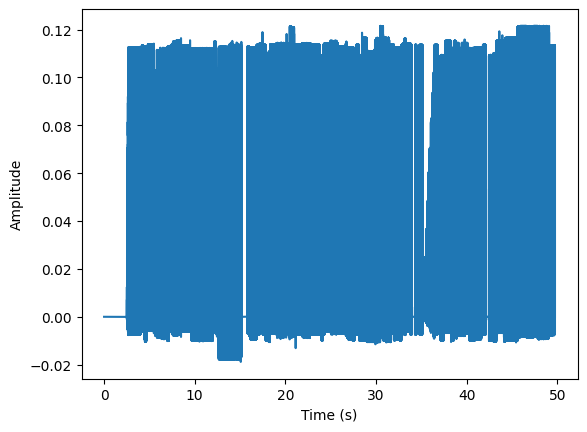

In [29]:
t_axis = np.linspace(0, x1.shape[0]/srate, x1.shape[0])
plt.plot(t_axis, x1)
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.show()

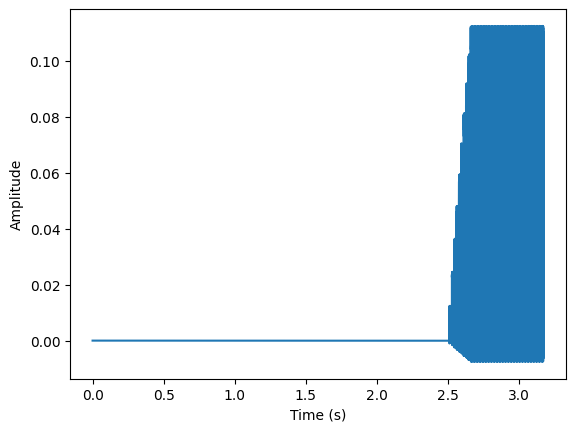

In [30]:
cutoff = 70000
t_axis = np.linspace(0, cutoff/srate, cutoff)
plt.plot(t_axis, x1[:cutoff])
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.show()

In [31]:
print(x1[68000:70000])

[ 2.50485353e-03 -2.25138664e-03  2.26345658e-03 -2.59618461e-03
  3.50899994e-03 -5.86045906e-03  7.94386864e-02  1.12221092e-01
  1.00767843e-01  1.08007260e-01  1.02597930e-01  1.06938019e-01
  1.03343114e-01  1.06352963e-01  1.03841089e-01  1.05906487e-01
  1.04253940e-01  1.05518751e-01  1.04619764e-01  1.05174676e-01
  1.04940377e-01  1.04880273e-01  1.05205201e-01  1.04648769e-01
  1.05399713e-01  1.04494855e-01  1.05509542e-01  1.04432441e-01
  1.05521210e-01  1.04474992e-01  1.05420657e-01  1.04637608e-01
  1.05194420e-01  1.04907751e-01  1.05078392e-01  1.01396933e-01
  1.65577903e-02 -4.15623048e-03  2.19603209e-03 -1.41026825e-03
  9.59414989e-04 -6.42392784e-04  3.77751887e-04 -7.84955919e-05
 -5.98426908e-04  6.33644685e-03  9.15147811e-02  1.08265325e-01
  1.03069752e-01  1.06440604e-01  1.03733853e-01  1.06094159e-01
  1.03971049e-01  1.05892964e-01  1.04166895e-01  1.05688728e-01
  1.04385525e-01  1.05453931e-01  1.04635790e-01  1.05190344e-01
  1.04909591e-01  1.04909

# Experiments with percussion track

Use amplitudes to map notes onto midi notes [0,1-16] (1-16 just to show increasing relative frequencies, like kick v snare drum) and then when parsing midi, treat notes 1-16 differently so you can actually hear them.

In [32]:
track4 = "093_DuckTales_06_07TheMoon_Track4.wav"
(x4,srate) = librosa.load(track4)
print("sampling rate =", srate)
ipd.Audio(x4, rate=srate)

sampling rate = 22050


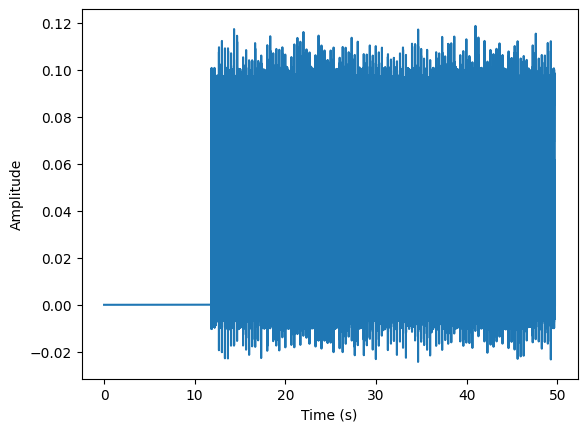

In [33]:
t_axis = np.linspace(0, x4.shape[0]/srate, x4.shape[0])
plt.plot(t_axis, x4)
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.show()

non-negative matrix factorization